# 03 - Wine classification: scaling, PCA and SVMs

13 chemical measurements, 3 cultivars. The lesson: **feature scaling decides whether distance- and gradient-based models work**, and PCA reveals why the problem is easy.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
import mlforge
from mlforge import visualization as viz
print("MLForge", mlforge.__version__)

MLForge 0.2.0


In [2]:
from sklearn.datasets import load_wine
d = load_wine(); X, y = d.data, d.target
print(X.shape, "feature scales (std):", np.round(X.std(0)[:6], 2), "...")
from mlforge.preprocessing import train_test_split, StandardScaler
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=0, stratify=y)

(178, 13) feature scales (std): [ 0.81  1.11  0.27  3.33 14.24  0.62] ...


## Scaling matters
The proline column is ~1000x larger than the others, so it dominates Euclidean distances and wrecks unscaled KNN / SVM.

In [3]:
from mlforge import Pipeline
from mlforge.neighbors import KNeighborsClassifier
from mlforge.svm import SVC
from mlforge.linear_model import SoftmaxRegression
for name, est in {"KNN": KNeighborsClassifier(5), "SVM (RBF)": SVC(random_state=0), "Softmax reg.": SoftmaxRegression(n_iters=300)}.items():
    raw = est.clone().fit(Xtr, ytr).score(Xte, yte)
    scaled = Pipeline([("sc", StandardScaler()), ("m", est.clone())]).fit(Xtr, ytr).score(Xte, yte)
    print(f"{name:<14} raw features: {raw:.3f}   standardised: {scaled:.3f}")

KNN            raw features: 0.709   standardised: 0.982
SVM (RBF)      raw features: 0.709   standardised: 0.982
Softmax reg.   raw features: 0.473   standardised: 1.000


## PCA: why it is easy
Two components capture most variance and separate the cultivars.

variance explained by first 2 / 3 / 5 components: 0.554 0.665 0.802
components for 95% variance: 10


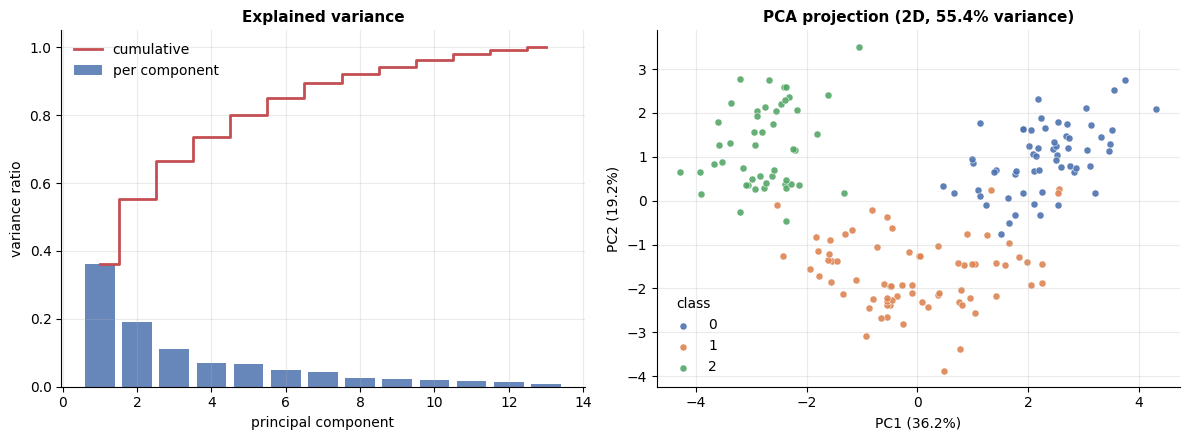

In [4]:
from mlforge.decomposition import PCA
Z = StandardScaler().fit_transform(X)
pca = PCA(None).fit(Z)
print("variance explained by first 2 / 3 / 5 components:", pca.explained_variance_ratio_[:2].sum().round(3), pca.explained_variance_ratio_[:3].sum().round(3), pca.explained_variance_ratio_[:5].sum().round(3))
print("components for 95% variance:", PCA(0.95).fit(Z).n_components_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
viz.plot_explained_variance(pca, ax=ax[0]); viz.plot_pca(Z, y, n_components=2, ax=ax[1]); plt.tight_layout()

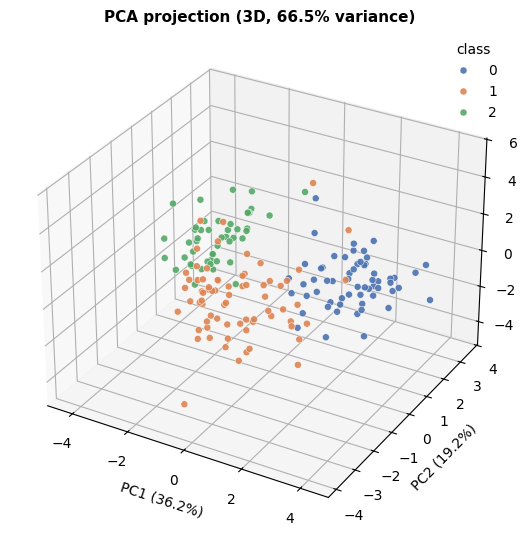

In [5]:
_ = viz.plot_pca(Z, y, n_components=3)

## Classifiers in PCA space and kernel choice

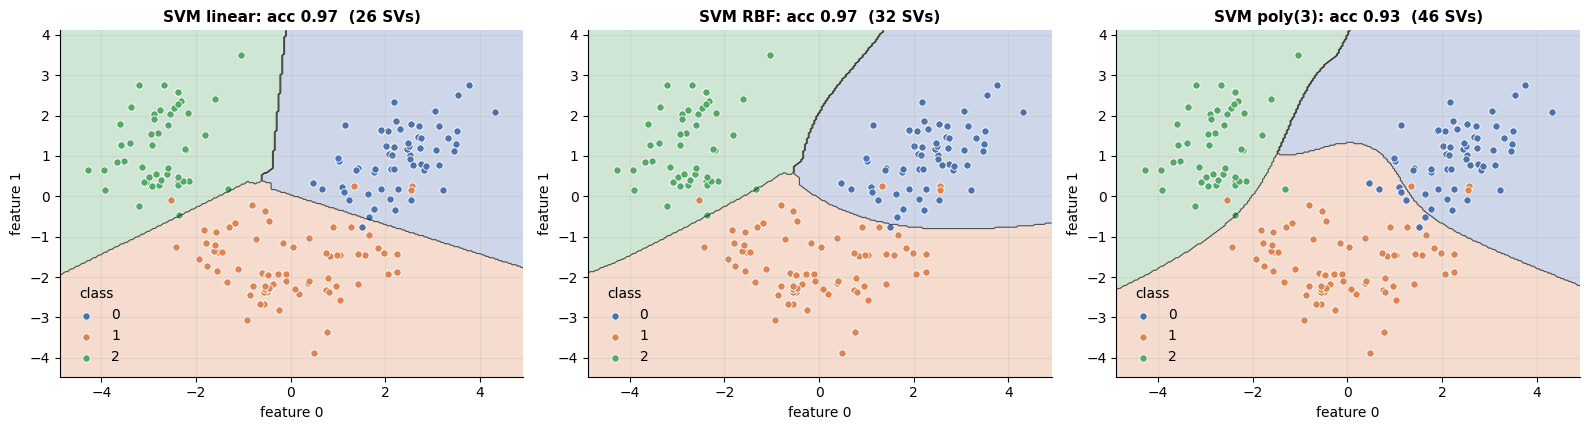

In [6]:
P2 = PCA(2).fit_transform(Z)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (name, m) in zip(axes, {"linear": SVC(kernel="linear", random_state=0), "RBF": SVC(C=3, random_state=0), "poly(3)": SVC(kernel="poly", C=3, random_state=0)}.items()):
    m.fit(P2, y); viz.plot_decision_boundary(m, P2, y, ax=ax, title=f"SVM {name}: acc {m.score(P2, y):.2f}  ({len(m.support_)} SVs)")
plt.tight_layout()

## Tuning the SVM with cross-validated grid search

In [7]:
from mlforge.model_selection import GridSearchCV
pipe = Pipeline([("sc", StandardScaler()), ("svm", SVC(random_state=0))])
gs = GridSearchCV(pipe, {"svm__C": [0.1, 1, 10], "svm__gamma": [0.003, 0.01, 0.03, 0.1]}, cv=4).fit(Xtr, ytr)
print("best:", gs.best_params_, " cv acc:", round(gs.best_score_, 3), " test acc:", round(gs.score(Xte, yte), 3))
res = gs.cv_results_; print("worst candidate cv acc:", res["mean_test_score"].min().round(3), "(hyper-parameters matter)")

best: {'svm__C': 1, 'svm__gamma': 0.03}  cv acc: 0.983  test acc: 1.0
worst candidate cv acc: 0.398 (hyper-parameters matter)


## Probabilistic baseline
Gaussian Naive Bayes is trivially fast and strong here; its probabilities are inspectable.

In [8]:
from mlforge.bayes import GaussianNB
from mlforge.metrics import log_loss, classification_report
nb = GaussianNB().fit(Xtr, ytr)
print("NB test acc:", round(nb.score(Xte, yte), 3), " log-loss:", round(log_loss(yte, nb.predict_proba(Xte)), 3))
print(classification_report(yte, nb.predict(Xte)))

NB test acc: 0.982  log-loss: 0.057
              precision     recall   f1-score   support

           0       1.00       0.94       0.97        18
           1       0.96       1.00       0.98        22
           2       1.00       1.00       1.00        15

    accuracy                             0.98        55
   macro avg       0.99       0.98       0.98        55
weighted avg       0.98       0.98       0.98        55

